### Machine Learning | Assignment 3 - Evolutionary Algorithms

145873 | Sezer Tetik

#### Exercise 5

In [1]:
import random
import time
from collections import deque
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

**Setup from Exercises 1 and 2.** Each exercise is its own notebook, so the functions are repeated here unchanged:

- from Exercise 1: the pattern generator and brute force (with the `solved` return value added in 2b);
- from Exercise 2: the fitness (number of matching bits), the one-bit mutation, hill climbing, and its expected number of mutations $n\,E[H_K]$.

The settings are also the same: 24-bit patterns, seeds 0–29 (the target is the first draw of each seed, so every method searches for the same 30 targets), sizes 2–24 bits and a budget of 1000 mutations.

In [2]:
SIZE = 24
SEEDS = list(range(30))
SIZES = [2, 4, 8, 12, 16, 20, 24]
MAX_MUTATIONS = 1000


def generate_random_pattern(size: int, rng: random.Random) -> str:
    if size < 1:
        raise ValueError("size must be >= 1")

    return format(rng.getrandbits(size), f"0{size}b")


def brute_force(target: str, rng: random.Random) -> tuple[int, float, bool]:
    size = len(target)
    attempts = 0
    start = time.perf_counter()

    while True:
        attempts += 1

        if generate_random_pattern(size, rng) == target:
            return attempts, time.perf_counter() - start, True

In [3]:
def fitness(guess: str, target: str) -> int:
    if len(guess) != len(target):
        raise ValueError("guess and target must have the same size")

    return sum(g == t for g, t in zip(guess, target))


def mutate(pattern: str, rng: random.Random) -> str:
    i = rng.randrange(len(pattern))
    flipped = "1" if pattern[i] == "0" else "0"

    return pattern[:i] + flipped + pattern[i + 1 :]


def hill_climbing(target: str, rng: random.Random, max_mutations: int = MAX_MUTATIONS) -> tuple[int, float, bool]:
    size = len(target)
    start = time.perf_counter()

    current = generate_random_pattern(size, rng)
    current_fitness = fitness(current, target)
    mutations = 0

    while current_fitness < size and mutations < max_mutations:
        candidate = mutate(current, rng)
        candidate_fitness = fitness(candidate, target)
        mutations += 1

        if candidate_fitness > current_fitness:
            current, current_fitness = candidate, candidate_fitness

    return mutations, time.perf_counter() - start, current_fitness == size


def expected_hc_mutations(n: int) -> float:
    return sum(comb(n, k) / 2**n * n * sum(1 / j for j in range(1, k + 1)) for k in range(n + 1))

**Tabu search: design and Tabu rule**

Tabu search is a local search with a short-term memory, the *tabu list*, of recent moves that are forbidden for a while. Here a move is flipping the bit at one position, as in the hill climber of Exercise 2. Everything else stays the same as that hill climber: random start, one random flip per step, the mutant kept only if its fitness is strictly higher, and the same stopping rule (solution found or 1000 mutations).

> **Tabu rule.** After a position has been flipped, whether the mutation was accepted or rejected, it becomes **tabu for the next $T$ mutations** (the *tenure*). Each mutation picks its position at random among the positions that are not tabu. The default tenure is $T = n - 1$: a position cannot be tried again until every other position has been tried.

Why this rule works for this problem (it builds on the analysis in 2c, where one flip changes the fitness by exactly $\pm 1$):

- **Rejected flip at position $i$:** the fitness dropped, so bit $i$ was already right. Trying $i$ again gives the same rejection, so it is a wasted evaluation. The hill climber draws positions *with* replacement and does this all the time: in 2b, around 80% of its mutations were rejected, most of them re-tries of bits already known to be right.
- **Accepted flip at position $i$:** bit $i$ is now right, and flipping it back would undo the move ($-1$, rejected). Forbidding the reverse of a recent move is the classic tabu rule that stops a search from going in circles.
- **Either way, one try at a position is enough.** Afterwards bit $i$ is known to be right and stays right, so the memory is never wrong, and the longest possible tenure is the best one. With $T = n - 1$ the positions are tried in a random order without repetition, so the search finishes after **at most $n$ mutations**.

Two standard tabu-search ingredients are deliberately left out:

- **Moving to a worse neighbour.** Classic tabu search moves to the best allowed neighbour even when it is worse, to escape local maxima. Exercise 2c showed that this landscape has none, so accepting a worse pattern would only undo progress. The memory's job here is to avoid repeated evaluations, not to escape local maxima.
- **Aspiration criterion.** Normally a tabu move is allowed anyway if it would beat the best pattern found so far. Here a tabu position is always a bit that is already right, so flipping it can never improve. The criterion would never fire and would only cost evaluations.

With $T = 0$ nothing is ever tabu and the search is exactly the hill climber of Exercise 2.

**Expected cost.** With $T = n - 1$ the tried positions form a random permutation, and the search ends when the last of the $K$ wrong bits has been tried. That is the largest of $K$ random positions out of $n$, with mean $K\frac{n+1}{K+1}$. Averaging over a random start, $K \sim \text{Binomial}(n, 1/2)$, gives

$$E[\text{mutations}] = \sum_{k=0}^{n} \binom{n}{k}\, 2^{-n}\, \frac{k\,(n+1)}{k+1} = n - 1 + 2^{-n} \approx n - 1$$

which is linear in $n$, with $n$ as the worst case. For comparison, hill climbing needs $n\,E[H_K] \approx n(\ln\frac{n}{2} + 0.58)$ and brute force $2^n$. At 24 bits that is 23 against 74 against 16.8 million.

In [4]:
def flip(pattern: str, i: int) -> str:
    return pattern[:i] + ("1" if pattern[i] == "0" else "0") + pattern[i + 1 :]


def tabu_search(
    target: str, rng: random.Random, tenure: int | None = None, max_mutations: int = MAX_MUTATIONS
) -> tuple[int, float, bool]:
    size = len(target)
    tenure = size - 1 if tenure is None else tenure
    if not 0 <= tenure < size:
        raise ValueError("tenure must be between 0 and size - 1")

    start = time.perf_counter()

    current = generate_random_pattern(size, rng)
    current_fitness = fitness(current, target)
    tabu = deque()  # tabu positions, oldest first
    tabu_set = set()
    mutations = 0

    while current_fitness < size and mutations < max_mutations:
        allowed = [i for i in range(size) if i not in tabu_set]
        i = allowed[rng.randrange(len(allowed))]
        candidate = flip(current, i)
        candidate_fitness = fitness(candidate, target)
        mutations += 1

        if candidate_fitness > current_fitness:
            current, current_fitness = candidate, candidate_fitness

        if tenure > 0:  # position i is tabu for the next `tenure` mutations
            tabu.append(i)
            tabu_set.add(i)
            if len(tabu) > tenure:
                tabu_set.discard(tabu.popleft())

    return mutations, time.perf_counter() - start, current_fitness == size

**Comparison with Exercises 1 and 2.** The setup is the same as in 2b, now with a third method:

- **Same targets:** seeds 0–29, target = first draw, for every method and size.
- **Same unit of work:** patterns tried (checked against the target). For brute force that is the number of attempts. For hill climbing and Tabu search it is the random start plus one pattern per mutation, rejected ones included.
- **Same timing:** `time.perf_counter()` from the first generated pattern until the search stops.
- **Same sizes:** 2–24 bits. Brute force reproduces the attempt counts of Exercise 1 and hill climbing those of Exercise 2.

In [6]:
METHODS = {"Brute force": brute_force, "Hill climbing": hill_climbing, "Tabu search": tabu_search}


def run_trials(search, size: int) -> dict:
    counts, times, solved = [], [], []

    for seed in SEEDS:
        rng = random.Random(seed)
        target = generate_random_pattern(size, rng)
        count, elapsed, ok = search(target, rng)

        counts.append(count)
        times.append(elapsed)
        solved.append(ok)

    return {"count": np.array(counts), "time": np.array(times), "solved": np.array(solved)}


results = {method: {} for method in METHODS}

for size in SIZES:
    for method, search in METHODS.items():
        results[method][size] = run_trials(search, size)

    # patterns checked against the target: brute force = attempts, the local searches = random start + mutations
    results["Brute force"][size]["tried"] = results["Brute force"][size]["count"]
    for method in ["Hill climbing", "Tabu search"]:
        results[method][size]["tried"] = results[method][size]["count"] + 1

    bf, hc, ts = (results[m][size] for m in METHODS)
    print(
        f"{size:>2} bits | brute force {bf['time'].sum():7.2f} s"
        f" | hill climbing {hc['time'].sum() * 1e3:5.2f} ms, {hc['solved'].sum()}/{len(SEEDS)} solved"
        f" | tabu search {ts['time'].sum() * 1e3:5.2f} ms, {ts['solved'].sum()}/{len(SEEDS)} solved"
    )

 2 bits | brute force    0.00 s | hill climbing  0.10 ms, 30/30 solved | tabu search  0.08 ms, 30/30 solved
 4 bits | brute force    0.00 s | hill climbing  0.23 ms, 30/30 solved | tabu search  0.19 ms, 30/30 solved
 8 bits | brute force    0.00 s | hill climbing  0.94 ms, 30/30 solved | tabu search  0.42 ms, 30/30 solved
12 bits | brute force    0.04 s | hill climbing  1.21 ms, 30/30 solved | tabu search  0.72 ms, 30/30 solved
16 bits | brute force    0.68 s | hill climbing  2.19 ms, 30/30 solved | tabu search  1.27 ms, 30/30 solved
20 bits | brute force    7.97 s | hill climbing  2.89 ms, 30/30 solved | tabu search  1.61 ms, 30/30 solved
24 bits | brute force   96.52 s | hill climbing  4.05 ms, 30/30 solved | tabu search  2.17 ms, 30/30 solved


In [7]:
COLORS = {"Brute force": "#2a78d6", "Hill climbing": "#eb6834", "Tabu search": "#1baf7a"}
MUTED = "#898781"
GRID = "#e1e0d9"
INK = "#52514e"


def style_axes(ax, title, xlabel, ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", which="major", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK)


def boxplot(ax, data, positions, color, width):
    fill = to_rgba(color, 0.2)
    ax.boxplot(
        data,
        positions=positions,
        widths=width,
        patch_artist=True,
        showmeans=True,
        boxprops={"facecolor": fill, "edgecolor": color, "linewidth": 1},
        medianprops={"color": color, "linewidth": 2},
        whiskerprops={"color": color, "linewidth": 1},
        capprops={"color": color, "linewidth": 1},
        flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "none", "markeredgecolor": MUTED},
        meanprops={"marker": "D", "markersize": 5, "markerfacecolor": "white", "markeredgecolor": color},
    )
    return Patch(facecolor=fill, edgecolor=color)


MEAN_HANDLE = Line2D(
    [], [], marker="D", linestyle="none", markerfacecolor="white", markeredgecolor=MUTED,
    label="Mean (box = IQR, line = median, whiskers = 1.5 IQR)",
)


def grouped_boxplot(metric, title, ylabel, baselines=None, cap=None):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    x = np.arange(len(SIZES))
    width = 0.8 / len(COLORS)
    handles = []

    for j, (method, color) in enumerate(COLORS.items()):
        positions = x + (j - (len(COLORS) - 1) / 2) * width
        patch = boxplot(ax, [results[method][s][metric] for s in SIZES], positions, color, width * 0.85)
        patch.set_label(method)
        handles.append(patch)

        if baselines is not None:
            label, values = baselines[method]
            ax.plot(positions, values, color=color, linewidth=1.5, linestyle="--", marker="o", markersize=3, zorder=1)
            handles.append(Line2D([], [], color=color, linewidth=1.5, linestyle="--", label=label))

    if cap is not None:
        ax.axhline(cap, color=MUTED, linewidth=1, linestyle=":", zorder=0)
        handles.append(Line2D([], [], color=MUTED, linewidth=1, linestyle=":", label=f"Local-search cap (1 + {MAX_MUTATIONS} mutations)"))

    handles.append(MEAN_HANDLE)
    ax.set_yscale("log")
    ax.set_xticks(x, SIZES)
    style_axes(ax, title, "Pattern size (bits)", ylabel)
    ax.legend(handles=handles, frameon=False, loc="upper left")

    plt.show()

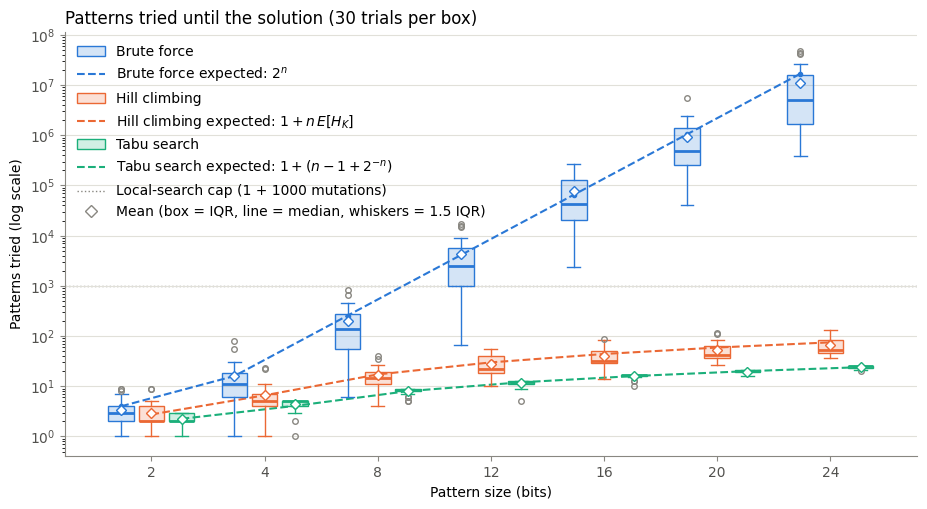

In [8]:
grouped_boxplot(
    "tried",
    title=f"Patterns tried until the solution ({len(SEEDS)} trials per box)",
    ylabel="Patterns tried (log scale)",
    baselines={
        "Brute force": ("Brute force expected: $2^n$", [2**s for s in SIZES]),
        "Hill climbing": ("Hill climbing expected: $1 + n\\,E[H_K]$", [1 + expected_hc_mutations(s) for s in SIZES]),
        "Tabu search": ("Tabu search expected: $1 + (n - 1 + 2^{-n})$", [s + 2.0**-s for s in SIZES]),
    },
    cap=1 + MAX_MUTATIONS,
)

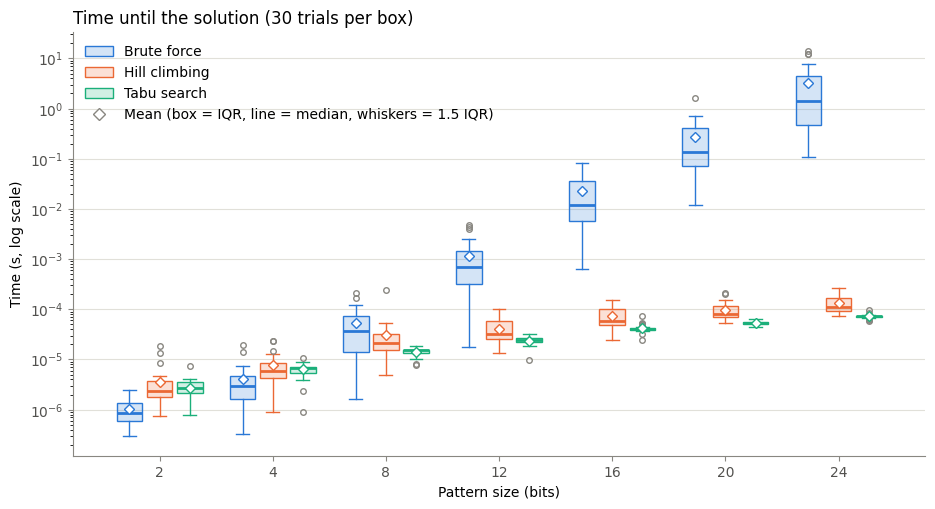

In [9]:
grouped_boxplot(
    "time",
    title=f"Time until the solution ({len(SEEDS)} trials per box)",
    ylabel="Time (s, log scale)",
)

**Effect of the tenure.** The tenure $T$ sets how much the Tabu search remembers. $T = 0$ is plain hill climbing, and $T = n - 1$ never re-tries a position before all the others have been tried. This sweep runs the same 30 targets at 24 bits for several tenures.

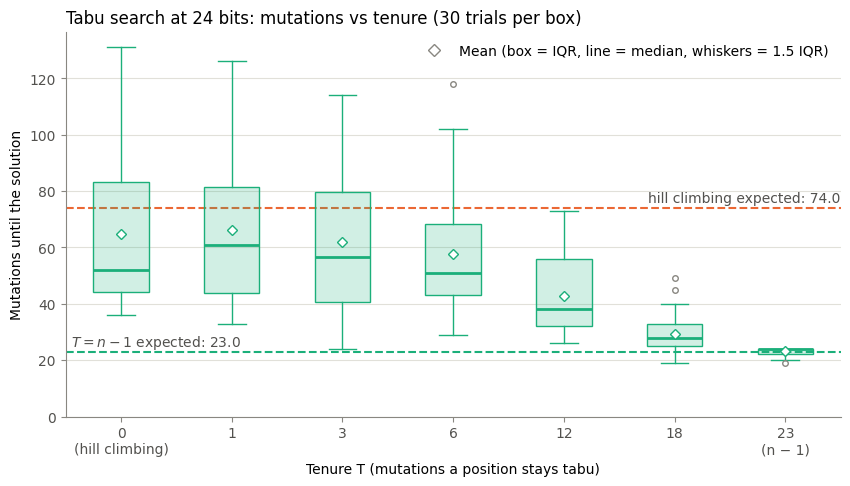

tenure,0,1,3,6,12,18,23
mean mutations,64.6,66.1,61.9,57.8,42.9,29.3,23.1
max,131.0,126.0,114.0,118.0,73.0,49.0,24.0


In [10]:
TENURES = [0, 1, 3, 6, 12, 18, SIZE - 1]
sweep = {}

for tenure in TENURES:
    counts = []

    for seed in SEEDS:
        rng = random.Random(seed)
        target = generate_random_pattern(SIZE, rng)
        counts.append(tabu_search(target, rng, tenure=tenure)[0])

    sweep[tenure] = np.array(counts)

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(TENURES))
boxplot(ax, [sweep[t] for t in TENURES], positions, COLORS["Tabu search"], 0.5)

for label, value, color, x, ha in [
    ("hill climbing expected", expected_hc_mutations(SIZE), COLORS["Hill climbing"], len(TENURES) - 0.5, "right"),
    ("$T = n - 1$ expected", SIZE - 1 + 2**-SIZE, COLORS["Tabu search"], -0.45, "left"),
]:
    ax.axhline(value, color=color, linewidth=1.5, linestyle="--", zorder=0)
    ax.annotate(f"{label}: {value:.1f}", xy=(x, value), xytext=(0, 4), textcoords="offset points", ha=ha, color=INK)

labels = [f"{t}\n(hill climbing)" if t == 0 else f"{t}\n(n − 1)" if t == SIZE - 1 else str(t) for t in TENURES]
ax.set_xticks(positions, labels)
ax.set_ylim(0, None)
style_axes(ax, f"Tabu search at {SIZE} bits: mutations vs tenure ({len(SEEDS)} trials per box)", "Tenure T (mutations a position stays tabu)", "Mutations until the solution")
ax.legend(handles=[MEAN_HANDLE], frameon=False, loc="upper right")

plt.show()

pd.DataFrame({"tenure": TENURES, "mean mutations": [sweep[t].mean() for t in TENURES], "max": [sweep[t].max() for t in TENURES]}).set_index("tenure").T.round(1)

Summary per pattern size. `TS expected` is $n - 1 + 2^{-n}$, the `÷ TS` columns say how many times more patterns or time each method needs than Tabu search, and `µs / pattern` is the cost of trying one pattern.

In [11]:
rows = []

for size in SIZES:
    bf, hc, ts = (results[m][size] for m in METHODS)

    rows.append({
        "bits": size,
        "BF mean attempts": bf["count"].mean(),
        "HC mean mutations": hc["count"].mean(),
        "TS mean mutations": ts["count"].mean(),
        "TS expected": size - 1 + 2**-size,
        "TS max": ts["count"].max(),
        "tried BF ÷ TS": bf["tried"].mean() / ts["tried"].mean(),
        "tried HC ÷ TS": hc["tried"].mean() / ts["tried"].mean(),
        "BF mean time (s)": bf["time"].mean(),
        "HC mean time (s)": hc["time"].mean(),
        "TS mean time (s)": ts["time"].mean(),
        "time HC ÷ TS": hc["time"].mean() / ts["time"].mean(),
        "HC µs / pattern": hc["time"].sum() / hc["tried"].sum() * 1e6,
        "TS µs / pattern": ts["time"].sum() / ts["tried"].sum() * 1e6,
        "TS solved": f"{ts['solved'].sum()}/{len(SEEDS)}",
    })

summary = pd.DataFrame(rows).set_index("bits")

pd.set_option("display.float_format", "{:.3g}".format)
summary

,BF mean attempts,HC mean mutations,TS mean mutations,TS expected,TS max,tried BF ÷ TS,tried HC ÷ TS,BF mean time (s),HC mean time (s),TS mean time (s),time HC ÷ TS,HC µs / pattern,TS µs / pattern,TS solved
bits,,,,,,,,,,,,,,
2,3.4,1.9,1.23,1.25,2,1.52,1.3,1.03e-06,3.5e-06,2.73e-06,1.28,1.21,1.22,30/30
4,15.7,5.73,3.4,3.06,4,3.57,1.53,4.08e-06,7.63e-06,6.36e-06,1.2,1.13,1.44,30/30
8,199,15.4,7.07,7,8,24.7,2.03,5.25e-05,3.13e-05,1.41e-05,2.22,1.91,1.75,30/30
12,4.3e+03,26.8,10.6,11,12,370,2.39,0.00117,4.03e-05,2.38e-05,1.69,1.45,2.05,30/30
16,7.79e+04,38.9,15,15,16,4.86e+03,2.49,0.0225,7.29e-05,4.23e-05,1.72,1.83,2.64,30/30
20,9.26e+05,50.7,18.6,19,20,4.73e+04,2.64,0.266,9.63e-05,5.35e-05,1.8,1.86,2.73,30/30
24,1.12e+07,64.6,23.1,23,24,4.64e+05,2.72,3.22,0.000135,7.24e-05,1.86,2.06,3.01,30/30


**Discussion**

*Patterns tried.* All three methods follow their theory lines. Brute force grows like $2^n$, hill climbing like $n \log n$, and Tabu search like $n - 1$. At 24 bits Tabu search needs 23.1 mutations on average (expected 23.0) and never more than 24, against 64.6 for hill climbing and 11.2 million attempts for brute force. In patterns tried, that makes it 2.7× cheaper than hill climbing and about 460,000× cheaper than brute force. The advantage over hill climbing grows slowly with the size, from 1.3× at 2 bits to 2.7× at 24 bits, because the coupon-collector waste that the tabu list removes grows like $\log n$. The ratio of the two expectations is roughly $\ln\frac{n}{2} + 0.58$, which is 3.2 at 24 bits (74 against 23). The measured 2.7 is lower only because these 30 hill-climbing runs happen to average below their expected 74 (64.6, about 1.9 standard errors low, as discussed in 2b).

*Spread.* The Tabu boxes are almost flat (24 bits: at most 24 mutations), because the rule caps the search at $n$ mutations. Hill climbing ranges from 36 to 131 mutations and brute force over two orders of magnitude. All 210 Tabu runs found the solution. Tabu search is not only faster on average but also predictable, with a guaranteed worst case of $n$.

*Time.* The time gain is smaller than the gain in patterns tried. At 24 bits Tabu search takes about 74 µs per run against about 132 µs for hill climbing (1.8× faster), and about 3.1 s for brute force (roughly 40,000× slower). The reason is that each Tabu step costs more: it builds the list of allowed positions, an $O(n)$ loop, before every mutation, so one pattern costs 1.2–3.1 µs against 1.0–2.0 µs for hill climbing. For $T = n - 1$ this overhead could be removed by shuffling the positions once (`rng.shuffle`) and walking through them, which is equivalent. The general deque-and-set version is kept so that any tenure can be tested.

*Tenure.* A short memory barely helps: $T$ = 1, 3 or 6 give 66.1, 61.9 and 57.8 mutations, all within the noise of plain hill climbing (64.6; the standard error is about 5). The repeated tries of hill climbing are spread over the whole run, so a position drawn again usually left the list long ago. Only a memory that covers most of the $n$ positions removes them: $T = 12$ gives 42.9, $T = 18$ gives 29.3 and $T = n - 1$ gives 23.1. This fits the Tabu rule: with this fitness, a tried position is right for good, so the memory is never wrong and longer is always better.

*Is it the best possible?* For searches that flip one bit at a time, yes, on average. A flip only reveals whether that one bit was right, and the wrong bits are uniformly random, so no order of trying positions can find the last wrong bit sooner than $K\frac{n+1}{K+1}$ on average. Tabu search with $T = n - 1$ reaches exactly that by never wasting a mutation on a position it has already tried.

*Limits of the rule.* The permanent memory relies on the fitness being a sum over independent bits, the property shown in 2c. If bits interacted, or the fitness were noisy, a position tried once could be worth trying again later. Then a finite tenure, moves to worse neighbours to escape local maxima, and an aspiration criterion would be needed, as in classic Tabu search.

**Conclusion.** Tabu search is hill climbing plus a memory of the positions already tried. That turns the random draws with replacement of Exercise 2 into draws without replacement. It solves the 24-bit problem in at most 24 mutations (23 on average), 2.7× fewer patterns and 1.8× less time than hill climbing, and five to six orders of magnitude fewer patterns than brute force.